<a href="https://colab.research.google.com/github/elmehdimoufakkir/TP1_Apprentissage_Supervise/blob/main/TP1_Apprentissage_Supervise_Scikit_learn_ELMehdi_MOUFAKKIR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercice 1 — Régression : prédiction du tarif d'un trajet Uber

## Étape 1 : Chargement et exploration

In [ ]:
import pandas as pd

In [ ]:
data=pd.read_csv('uber.csv')
print(data.head())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [ ]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
None


In [ ]:
print(data.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


## Étape 2 : Nettoyage et préparation

In [ ]:
data = data.dropna()
data = data[data['fare_amount'] > 0]
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek

## Étape 3 : Séparation des données

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
import numpy as np

# Fonction pour calculer la distance de Haversine en kilomètres entre deux points GPS
def haversine_distance(lat1, lon1, lat2, lon2):
    # Conversion des degrés en radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    # Formule de Haversine
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    r = 6371  # Rayon de la Terre en kilomètres
    return c * r

# Création de la colonne 'distance'
data['distance'] = haversine_distance(
    data['pickup_latitude'],
    data['pickup_longitude'],
    data['dropoff_latitude'],
    data['dropoff_longitude']
)

# Nettoyage des distances aberrantes (ex: distances égales à 0 ou extrêmement grandes)
data = data[(data['distance'] > 0) & (data['distance'] < 100)]

# Vérification
print(data[['distance', 'hour', 'day_of_week', 'fare_amount']].head())

   distance  hour  day_of_week  fare_amount
0  1.683323    19            3          7.5
1  2.457590    20            4          7.7
2  5.036377    21            0         12.9
3  1.661683     8            4          5.3
4  4.475450    17            3         16.0


In [ ]:
X = data[['distance', 'hour', 'day_of_week']]
y = data['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

##Étape 4 : Entraînement du modèle

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
# 1. Création de l'instance du modèle de Regression
lr = LinearRegression()

In [ ]:
# 2. Entraînement du modèle sur les données d'entraînement
lr.fit(X_train, y_train)

LinearRegression()

In [ ]:
# 3. Prédiction des prix sur les données  de test
y_pred = lr.predict(X_test)

In [ ]:
print("Voici les 5 premières prédictions :")
print(y_pred[:5])

Voici les 5 premières prédictions :
[ 9.61380672  7.85122747  9.56987304  5.03632466 19.59509623]


## Étape 5 : Évaluation du modèle

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [ ]:
# Calcul les trois  métriques d'évaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

In [ ]:
print('les resultats de trois metriques')
print('MAE  =', mae)
print('RMSE =', rmse)
print('R²   =', r2)

les resultats de trois metriques
MAE  = 2.408089057187631
RMSE = 5.034749985774523
R²   = 0.7303873564149268


### Intérpretation :
MAE $\approx 2.41$ : En moyenne, le modèle se trompe de 2,41 $ sur le prix d'un trajet.

RMSE $\approx 5.03$ : L'erreur quadratique moyenne est de 5,03 $. La différence entre MAE et RMSE s'explique par le fait qu'il y a quelques trajets avec de grosses erreurs (par exemple à cause d'embouteillages ou de tarifs spéciaux).

$R^2 \approx 0.7304$ (73,04%) : le modèle de régression linéaire parvient à expliquer 73 % des variations du tarif Uber uniquement avec la distance, l'heure et le jour de la semaine. C'est un score très solide pour un modèle simple .

## Étape 6 : Amélioration avec Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [ ]:
# 1. Instanciation et entraînement du modèle (100 arbres)
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
# 2. Prédiction sur l'ensemble de test
y_pred_rf = rf.predict(X_test)

In [ ]:
# 3. Évaluation des performances
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

In [ ]:
print('--- Résultats Random Forest ---')
print('MAE  =', mae_rf)
print('RMSE =', rmse_rf)
print('R²   =', r2_rf)

--- Résultats Random Forest ---
MAE  = 2.5146223590684467
RMSE = 4.919209632866782
R²   = 0.7426198219362935


## Étape 7 : Visualisation des résultats

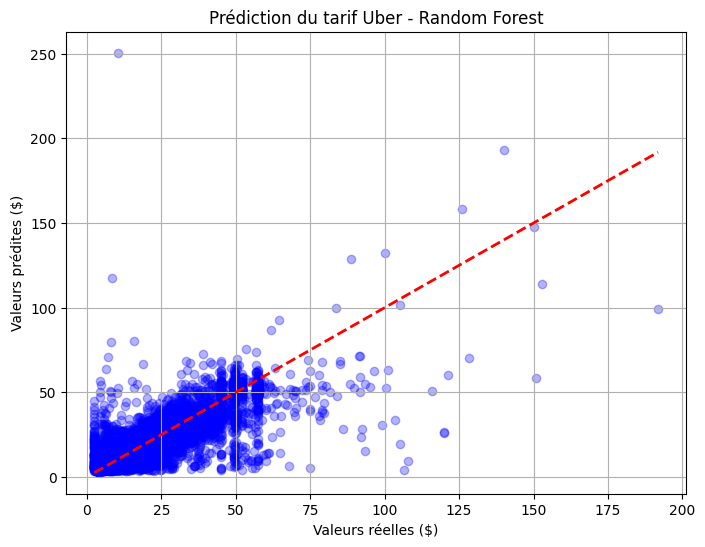

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Valeurs réelles ($)')
plt.ylabel('Valeurs prédites ($)')
plt.title('Prédiction du tarif Uber - Random Forest')
plt.grid(True)
plt.show()

#Exercice 2 — Classification : Prédire la survie sur le Titanic

##Étape 1 : Chargement et exploration

In [ ]:
data=pd.read_csv('Titanic-Dataset.csv')

In [ ]:
print(data.head())
print(data.info())
print(data.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

In [ ]:
print(data.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


In [ ]:
print(data.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


#Étape 2 : Nettoyage et traitement

In [ ]:
data = data[['Survived','Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']]
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

## Étape 3 : Encodage des variables catégorielles

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Instanciation de l'encodeur qui transforme valeur cetégorialle vers numérique
le = LabelEncoder()

# Transformation des colonnes textuelles en valeurs numériques
data['Sex'] = le.fit_transform(data['Sex'])
data['Embarked'] = le.fit_transform(data['Embarked'])

print(data.head())

   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
0         0       3    1  22.0      1      0   7.2500         2
1         1       1    0  38.0      1      0  71.2833         0
2         1       3    0  26.0      0      0   7.9250         2
3         1       1    0  35.0      1      0  53.1000         2
4         0       3    1  35.0      0      0   8.0500         2


## Étape 4 : Séparation des données

In [ ]:
X = data.drop('Survived', axis=1)
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

On va prendre tous les attributs de notre data sauf l'attribut survived que nous essayons de prédire

## Étape 5 : Entraînement des modèles

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Instanciation des modèles
log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Entraînement sur les données d'entraînement
log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

## Étape 6 : Évaluation des modèles

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# 1. Calcul des prédictions pour chaque modèle
y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# 2. Affichage des scores d'Accuracy
print('Accuracy (Régression Logistique) :', accuracy_score(y_test, y_pred_log))
print('Accuracy (Random Forest)        :', accuracy_score(y_test, y_pred_rf))

# 3. Rapport détaillé pour le Random Forest
print("\n--- Rapport de classification (Random Forest) ---")
print(classification_report(y_test, y_pred_rf))

Accuracy (Régression Logistique) : 0.8100558659217877
Accuracy (Random Forest)        : 0.8212290502793296

--- Rapport de classification (Random Forest) ---
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



Régression Logistique = 0.810 (81.01%) : Le modèle linéaire prédit correctement le statut de 81% des passagers.  

Random Forest = 0.821 (82.12%) : La forêt aléatoire obtient un meilleur score avec 82.12% de bonnes prédictions.  

Conclusion : Le Random Forest est plus performant car il gère mieux les relations non linéaires (ex: combinaison du sexe, de la classe et de l'âge).

## Étape 7 : Matrice de confusion

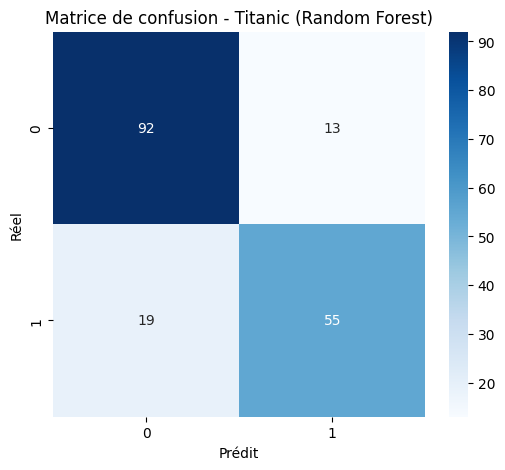

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calcul de la matrice de confusion pour Random Forest
cm = confusion_matrix(y_test, y_pred_rf)

# 2. Affichage avec Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion - Titanic (Random Forest)')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()

#Partie 2 : Mini-projet (Breast Cancer Wisconsin)

##Étape 1 : Chargement et exploration

In [ ]:
data=pd.read_csv('data.csv')

In [ ]:
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
data.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


##Étape 2 : Nettoyage et traitement

In [ ]:
# 1. Vérifier le nombre de lignes en double
print("Nombre de doublons avant nettoyage :", data.duplicated().sum())

# 2. Supprimer les doublons
data = data.drop_duplicates()

# 3. Vérifier la nouvelle taille du dataset
print("Nouvelle taille des données :", data.shape)

Nombre de doublons avant nettoyage : 0
Nouvelle taille des données : (569, 33)


##Étape 3 : Séparation des données

In [ ]:
# 1. Supprimer les colonnes inutiles
data = data.drop(columns=['id', 'Unnamed: 32'], errors='ignore')

# 2. Encoder la cible
data['diagnosis'] = data['diagnosis'].map({'B': 0, 'M': 1})

# 3. Séparer X et y
X = data.drop('diagnosis', axis=1)
y = data['diagnosis']

# 4. Vérifications (doivent afficher 0 et uniquement float64)
print('NaN restants :', X.isnull().sum().sum())
print('Types :', X.dtypes.unique())
print('Nombre de colonnes :', X.shape[1])   # doit être 30

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

NaN restants : 0
Types : [dtype('float64')]
Nombre de colonnes : 30


## Étape 4 : Entraînement des modèles

In [ ]:
log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

#### Étape 5 : Évaluation des modèles

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print('Accuracy (Logistic)     :', round(accuracy_score(y_test, y_pred_log), 4))
print('Accuracy (Random Forest):', round(accuracy_score(y_test, y_pred_rf), 4))
print('AUC (Logistic)          :', round(roc_auc_score(y_test, log_model.predict_proba(X_test)[:, 1]), 4))
print('AUC (Random Forest)     :', round(roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]), 4))

noms = ['Bénin (0)', 'Malin (1)']
print('\n--- Régression logistique ---')
print(classification_report(y_test, y_pred_log, target_names=noms))
print('--- Random Forest ---')
print(classification_report(y_test, y_pred_rf, target_names=noms))

Accuracy (Logistic)     : 0.9649
Accuracy (Random Forest): 0.9737
AUC (Logistic)          : 0.996
AUC (Random Forest)     : 0.9929

--- Régression logistique ---
              precision    recall  f1-score   support

   Bénin (0)       0.96      0.99      0.97        72
   Malin (1)       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

--- Random Forest ---
              precision    recall  f1-score   support

   Bénin (0)       0.96      1.00      0.98        72
   Malin (1)       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



**Interprétation** : on s'attend à ~95–98 % d'accuracy pour les deux modèles. Ce qui compte surtout ici est le **recall de la classe « Malin »** : parmi les vraies tumeurs malignes, combien sont détectées ? Un faux négatif (cancer non détecté) est bien plus grave qu'un faux positif (examen complémentaire inutile)

##Étape 7 : La Matrice de Confusion

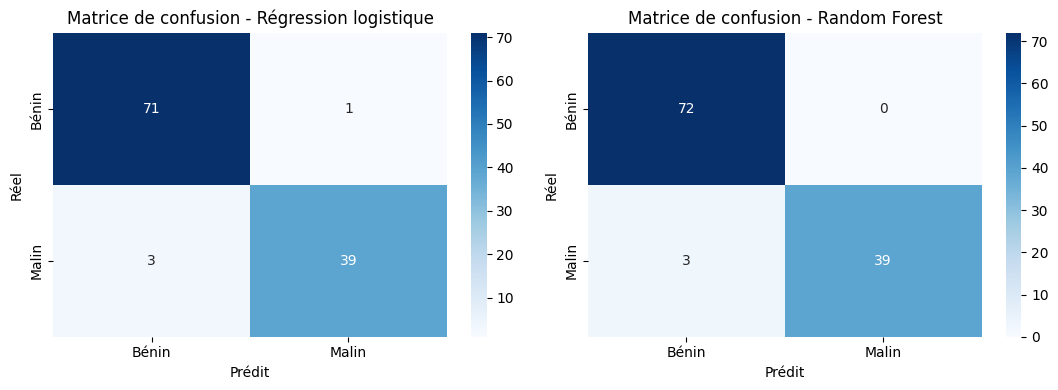

Random Forest -> VN=72  FP=0  FN=3 (cancers manqués)  VP=39


In [ ]:
from sklearn.metrics import confusion_matrix

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, pred, titre in [(ax[0], y_pred_log, 'Régression logistique'), (ax[1], y_pred_rf, 'Random Forest')]:
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=a,
                xticklabels=['Bénin', 'Malin'], yticklabels=['Bénin', 'Malin'])
    a.set_title(f'Matrice de confusion - {titre}')
    a.set_xlabel('Prédit'); a.set_ylabel('Réel')
plt.tight_layout(); plt.show()

# Lecture : [[VN, FP], [FN, VP]]
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_rf).ravel()
print(f'Random Forest -> VN={tn}  FP={fp}  FN={fn} (cancers manqués)  VP={tp}')

Les deux modèles atteignent plus de 96 % d’accuracy. Le Random Forest obtient légèrement de meilleurs résultats (aucune fausse alerte), mais la différence ne représente qu’un patient sur 114. Les deux modèles manquent 3 cancers sur 42 (recall = 92,9 %), ce qui reste le principal point faible en contexte médical où un faux négatif est plus grave qu’un faux positif. Le choix final doit donc se baser sur la validation croisée et sur le recall, et non sur l’accuracy seule.